In [1]:
%pylab inline

nzs=4
import gc
import glob
import fitsio
import anautil
import numpy as np
import matplotlib.cm as cm
import numpy.lib.recfunctions as rfn
fieldname='XMM'
outDir='/work/xiangchong.li/work/cosmicShear/s16a/photoz/'

Populating the interactive namespace from numpy and matplotlib


In [2]:
cd /work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/

/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut


In [66]:
def main(pzname,iz=0):
    datDir='/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/'
    pzDir=os.path.join(datDir,'catalog_tracts','XMM_tracts')
    pbins= pyfits.getdata(os.path.join(pzDir,'8522_pz_pdf_%s.fits' %pzname),ext=2)['BINS']
    inDir  =   os.path.join(datDir,'catalog_tracts','%s_tracts' %fieldname) 
    fnames=glob.glob(os.path.join(inDir,'*_pz_pdf_%s.fits' %(pzname)))
    pTest=[]
    for pfname in fnames[:10]:
        pata=pyfits.getdata(pfname)
        fname=pfname.split('pz_pdf')[0]+'pz.fits'
        data=pyfits.getdata(fname)
        if pzname != 'dempz':
            poz_best=data['%s_photoz_best' %pzname]
        else:
            poz_best=data['%s_photoz_best' %pzname[:-1]]
        del data,fname
        fname=pfname.split('pz_pdf')[0]+'no_m.fits'
        zmin=   (iz+1)*0.3
        zmax=   (iz+2)*0.3
        tmp_msk=(poz_best>zmin)&(poz_best<=zmax)
        pTest.append(pata[tmp_msk]['PDF'])
        del tmp_msk,pata
        gc.collect()
    pTest=np.vstack(pTest)
    out=np.log10(np.sum(pTest[:,pbins>2.],axis=1)/np.sum(pTest,axis=1))
    return pbins,pTest,out

# DNNZ

In [78]:
pb1,pTest1,out1=main('dnnz',iz=0)
pb2,pTest2,out2=main('dnnz',iz=1)
pb3,pTest3,out3=main('dnnz',iz=2)
pb4,pTest4,out4=main('dnnz',iz=3)
print(len(pb1))

/work/xiangchong.li/miniconda3/envs/cosmosis-mpich/lib/python3.7/site-packages/ipykernel_launcher.py:25: RuntimeWarning: divide by zero encountered in log10


100


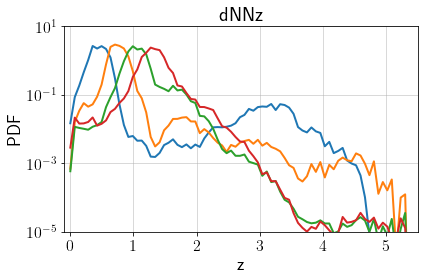

In [79]:
plt.close()
pStack1=np.average(pTest1,axis=0)
pStack2=np.average(pTest2,axis=0)
pStack3=np.average(pTest3,axis=0)
pStack4=np.average(pTest4,axis=0)
plt.plot(pb1,pStack1/(pb1[1]-pb1[0]))
plt.plot(pb2,pStack2/(pb1[1]-pb1[0]))
plt.plot(pb3,pStack3/(pb1[1]-pb1[0]))
plt.plot(pb4,pStack4/(pb1[1]-pb1[0]))
plt.yscale('log')
plt.ylim(1e-5,1e1)
plt.xlim(-0.1,5.5)
plt.xlabel('z')
plt.ylabel('PDF')
plt.title('dNNz',fontsize=20)
plt.grid()
plt.tight_layout()

nzList=[pStack1,pStack2,pStack3,pStack4]
t=anautil.make_nz_hdu(nzList,pb1)
#t.writeto(os.path.join(outDir,'HSC_Y3.fits'),overwrite=True)

In [51]:
if False:
    zlow=pb1-(pb1[1]-pb1[0])
    zmid=pb1
    zhigh=pb1+(pb1[1]-pb1[0])
    pStack1Ext=pStack1.copy()
    pStack1Ext[zmid>1.8]=pStack1Ext[zmid>1.8][0]*(pb1[zmid>1.8]/pb1[zmid>1.8][0])**-4

    plt.plot(pb1,pStack1Ext)
    plt.plot(pb2,pStack2)
    plt.plot(pb3,pStack3)
    plt.plot(pb4,pStack4)
    plt.yscale('log')
    plt.ylim(1e-7,3e-1)
    plt.xlim(-0.1,5.5)
    plt.xlabel('z')

    nzList=[pStack1Ext,pStack2,pStack3,pStack4]
    t=anautil.make_nz_hdu(nzList,pb1)
    del nzList
    gc.collect()
    t.writeto(os.path.join(outDir,'HSC_Y3_ext.fits'),overwrite=True)

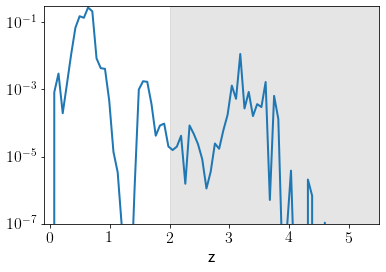

In [28]:
# single poz
plt.plot(pb1,pTest1[1])
plt.yscale('log')
plt.ylim(1e-7,3e-1)
plt.xlim(-0.1,5.5)
plt.xlabel('z')
plt.axvspan(2,10,alpha=0.2, color='grey')

0.02910323
with DNNZ \int{P(>2)}< 0.3162
0.012798807
with DNNZ \int{P(>2)}< 0.1585
0.004468135
with DNNZ \int{P(>2)}< 0.0631


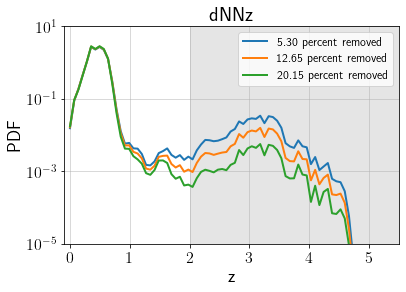

In [54]:
#stack
for thres in [-0.5,-.8,-1.2]:
    stackTmp=np.average(pTest1[out1<thres],axis=0)/(pb1[1]-pb1[0])
    print(np.sum(stackTmp[pb1>2.0])*(pb1[1]-pb1[0]))
    plt.plot(pb1,stackTmp,label='%.2f percent removed' %(100-np.sum(out1<thres)/len(out1)*100.))
    del stackTmp
    gc.collect()
    print(r'with DNNZ \int{P(>2)}< %.4f' %(10**(thres)))
plt.axvspan(2,10,alpha=0.2, color='grey')
plt.legend(loc='upper right',fontsize=12)
plt.title('dNNz',fontsize=20)
plt.yscale('log')
plt.ylabel('PDF')
plt.xlabel('z')
plt.ylim(1e-5,1e1)
plt.xlim(-0.1,5.5)
plt.grid()

# Dempz

In [72]:
pb1,pTest1,out1=main('dempz',iz=0)
pb2,pTest2,out2=main('dempz',iz=1)
pb3,pTest3,out3=main('dempz',iz=2)
pb4,pTest4,out4=main('dempz',iz=3)
print(len(pb1))

/work/xiangchong.li/miniconda3/envs/cosmosis-mpich/lib/python3.7/site-packages/ipykernel_launcher.py:25: RuntimeWarning: divide by zero encountered in log10


601


Text(0.5, 1.0, 'dempz')

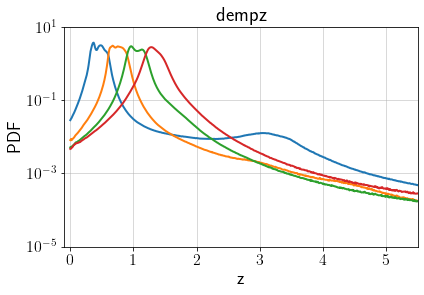

In [73]:
plt.close()
pstack1=np.average(pTest1,axis=0)
pstack2=np.average(pTest2,axis=0)
pstack3=np.average(pTest3,axis=0)
pstack4=np.average(pTest4,axis=0)
plt.plot(pb1,pstack1/(pb1[1]-pb1[0]))
plt.plot(pb2,pstack2/(pb1[1]-pb1[0]))
plt.plot(pb3,pstack3/(pb1[1]-pb1[0]))
plt.plot(pb4,pstack4/(pb1[1]-pb1[0]))
plt.yscale('log')
plt.ylim(1e-5,1e1)
plt.xlim(-0.1,5.5)
plt.xlabel('z')
plt.ylabel('PDF')
plt.grid()
plt.tight_layout()
plt.title('dempz',fontsize=20)

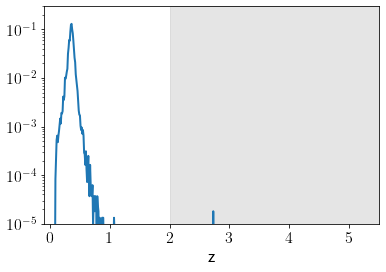

In [42]:
plt.plot(pb1,pTest1[1])
plt.yscale('log')
plt.ylim(1e-5,3e-1)
plt.xlim(-0.1,5.5)
plt.xlabel('z')
plt.axvspan(2,10,alpha=0.2, color='grey')

# Mizuki

In [74]:
pb1,pTest1,out1=main('mizuki',iz=0)
pb2,pTest2,out2=main('mizuki',iz=1)
pb3,pTest3,out3=main('mizuki',iz=2)
pb4,pTest4,out4=main('mizuki',iz=3)

/work/xiangchong.li/miniconda3/envs/cosmosis-mpich/lib/python3.7/site-packages/ipykernel_launcher.py:25: RuntimeWarning: divide by zero encountered in log10


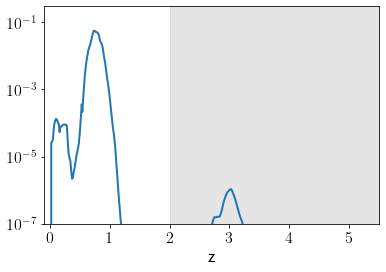

In [75]:
plt.plot(pb1,pTest2[2])
plt.yscale('log')
plt.ylim(1e-7,3e-1)
plt.xlim(-0.1,5.5)
plt.xlabel('z')
plt.axvspan(2,10,alpha=0.2, color='grey')

Text(0.5, 1.0, 'mizuki')

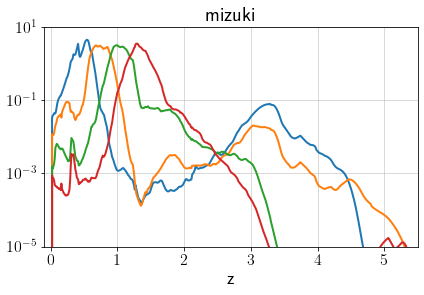

In [76]:
plt.close()
pstack1=np.average(pTest1,axis=0)
pstack2=np.average(pTest2,axis=0)
pstack3=np.average(pTest3,axis=0)
pstack4=np.average(pTest4,axis=0)

plt.plot(pb1,pstack1/(pb1[1]-pb1[0]))
plt.plot(pb2,pstack2/(pb1[1]-pb1[0]))
plt.plot(pb3,pstack3/(pb1[1]-pb1[0]))
plt.plot(pb4,pstack4/(pb1[1]-pb1[0]))
plt.yscale('log')
plt.ylim(1e-5,1e1)
plt.xlim(-0.1,5.5)
plt.grid()
plt.xlabel('z')
plt.tight_layout()
plt.title('mizuki',fontsize=20)

0.022452073
with MIZUKIZ P(>2) < 0.3162
0.0096602
with MIZUKIZ P(>2) < 0.1585
0.003267147
with MIZUKIZ P(>2) < 0.0631


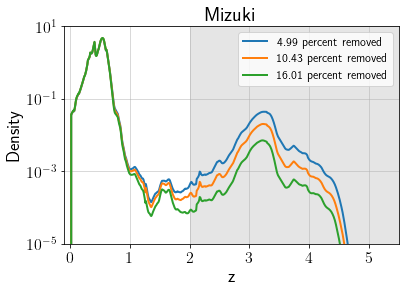

In [61]:
for thres in [-0.5,-.8,-1.2]:
    stackTmp=np.average(pTest1[out1<thres],axis=0)/(pb1[1]-pb1[0])
    print(np.sum(stackTmp[pb1>2.0])*(pb1[1]-pb1[0]))
    plt.plot(pb1,stackTmp,label='%.2f percent removed' %(100-np.sum(out1<thres)/len(out1)*100.))
    del stackTmp
    gc.collect()
    plt.yscale('log')
    plt.xlabel('z')
    print('with MIZUKIZ P(>2) < %.4f' %(10**(thres)))
    
plt.title('Mizuki',fontsize=20)
plt.ylabel('Density')
plt.ylim(1e-5,1e1)
plt.xlim(-0.1,5.5)
plt.axvspan(2,10,alpha=0.2, color='grey')
plt.legend(loc='upper right',fontsize=12)
plt.grid()